In [2]:
import cv2
from ultralytics import YOLO


In [9]:
# caminho dos pesos v8
caminho_peso_8 = "meus_modelos/alpr_yolov8n/weights/best.pt"

#escolher modelo
print(f"carregando modelo: {caminho_peso_8}")
modelo_v8 = YOLO(caminho_peso_8)


#caminho da imagem de teste
imagem_teste= "imagens_test/images/07bd977e-d578-49a2-b345-7cee5a4db6bf___new_1031520d1356604430-skoda-rapid-joins-family-edit-sold-wp_000281_jpg_jpeg.rf.32a5cf7b7c1c8c8e0933956a6239864d.jpg"

#resultado da inferencia
resultados = modelo_v8(imagem_teste, conf=0.5)

#processar e vizualizar
for resultado in resultados:
    imagem_anotada = resultado.plot()
    cv2.imshow("Detecção YOLO", imagem_anotada)
    cv2.waitKey(0)
    cv2.destroyAllWindows()


carregando modelo: meus_modelos/alpr_yolov8n/weights/best.pt

image 1/1 c:\Users\Larissa\Documents\SCTECH\ALPR_YOLO_V8\imagens_test\images\07bd977e-d578-49a2-b345-7cee5a4db6bf___new_1031520d1356604430-skoda-rapid-joins-family-edit-sold-wp_000281_jpg_jpeg.rf.32a5cf7b7c1c8c8e0933956a6239864d.jpg: 640x640 1 license_plate, 116.8ms
Speed: 2.4ms preprocess, 116.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)


#OCR


In [6]:
# Importa as bibliotecas necessárias
import cv2
import matplotlib.pyplot as plt
import easyocr
from ultralytics import YOLO

# Inicializa o OCR para reconhecer caracteres em português/inglês
leitor_ocr = easyocr.Reader(['en'], gpu=True)

Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.
c:\Users\Larissa\.pyenv\pyenv-win\versions\3.13.0\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(


Using CPU. Note: This module is much faster with a GPU.


Carregando modelo: meus_modelos/alpr_yolov8n/weights/best.pt
Imagem carregada com sucesso!

0: 640x640 1 license_plate, 135.8ms
Speed: 5.5ms preprocess, 135.8ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

Placa detectada: 1
Confiança YOLO: 88.51%
Texto reconhecido: HH12JC2813
Trecho: HH12JC2813 | Confiança OCR: 42.80%


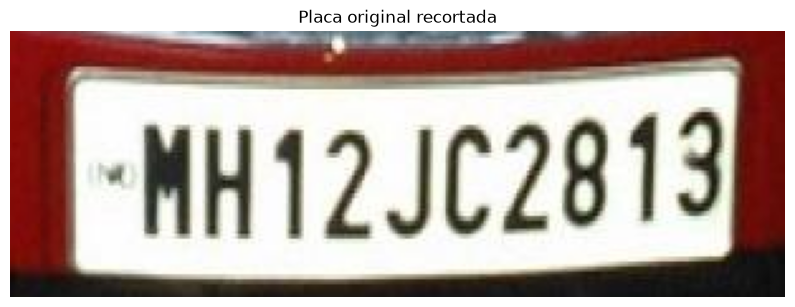

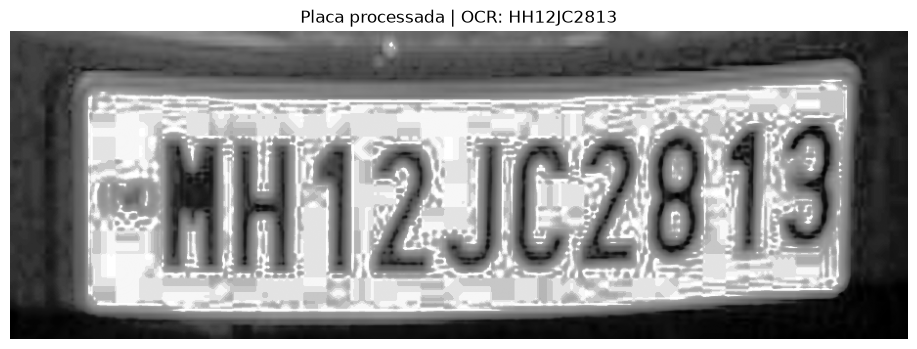

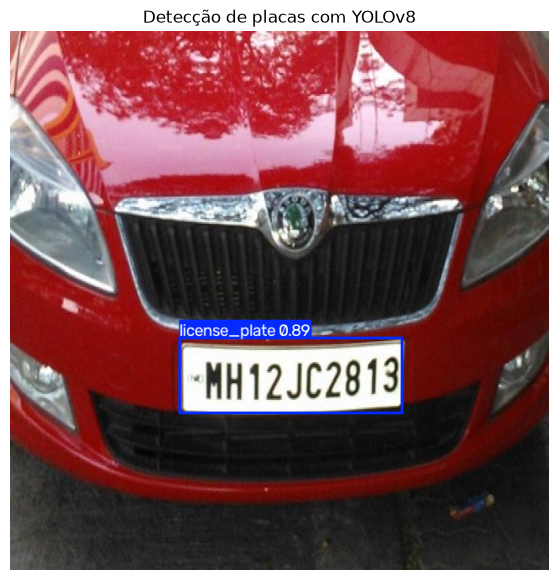


RESUMO DO RECONHECIMENTO
Placa 1: HH12JC2813


In [11]:

# ============================================================
# 1. IMPORTAR AS BIBLIOTECAS
# ============================================================

import cv2
import easyocr
import matplotlib.pyplot as plt
from ultralytics import YOLO


# ============================================================
# 2. CARREGAR O MODELO YOLOv8
# ============================================================

# Caminho dos pesos do modelo treinado
caminho_peso_8 = "meus_modelos/alpr_yolov8n/weights/best.pt"

print(f"Carregando modelo: {caminho_peso_8}")

# Carrega o modelo responsável por detectar as placas
modelo_v8 = YOLO(caminho_peso_8)


# ============================================================
# 3. INICIALIZAR O EASYOCR
# ============================================================

# Usa o idioma inglês, adequado para letras latinas e números
# gpu=False executa o OCR pela CPU no computador local
leitor_ocr = easyocr.Reader(["en"], gpu=False)


# ============================================================
# 4. CARREGAR A IMAGEM
# ============================================================

imagem_teste = (
    "imagens_test/images/"
    "07bd977e-d578-49a2-b345-7cee5a4db6bf___new_1031520d1356604430-"
    "skoda-rapid-joins-family-edit-sold-wp_000281_jpg_jpeg.rf."
    "32a5cf7b7c1c8c8e0933956a6239864d.jpg"
)

# Lê a imagem usando OpenCV
imagem = cv2.imread(imagem_teste)

# Verifica se a imagem foi encontrada
if imagem is None:
    raise FileNotFoundError(
        f"Não foi possível carregar a imagem: {imagem_teste}"
    )

print("Imagem carregada com sucesso!")


# ============================================================
# 5. DETECTAR AS PLACAS
# ============================================================

# O YOLO procura placas com confiança mínima de 50%
resultados = modelo_v8(imagem, conf=0.5)

# Lista para armazenar os textos reconhecidos
textos_reconhecidos = []


# ============================================================
# 6. PROCESSAR CADA DETECÇÃO
# ============================================================

for resultado in resultados:

    # Desenha as caixas delimitadoras na imagem
    imagem_anotada = resultado.plot()

    # Percorre todas as placas detectadas
    for indice, caixa in enumerate(resultado.boxes):

        # Obtém as coordenadas da caixa
        x1, y1, x2, y2 = map(
            int, caixa.xyxy[0].tolist()
        )

        # Confiança do YOLO na detecção
        confianca_yolo = float(caixa.conf[0])

        # Dimensões da imagem original
        altura, largura = imagem.shape[:2]

        # Calcula uma margem para evitar cortar as letras
        margem_x = int((x2 - x1) * 0.08)
        margem_y = int((y2 - y1) * 0.10)

        # Amplia o recorte respeitando os limites da imagem
        cx1 = max(0, x1 - margem_x)
        cy1 = max(0, y1 - margem_y)
        cx2 = min(largura, x2 + margem_x)
        cy2 = min(altura, y2 + margem_y)

        # Recorta a placa usando a imagem original
        placa = imagem[cy1:cy2, cx1:cx2]

        # Ignora o recorte se estiver vazio
        if placa.size == 0:
            print("Recorte vazio. Detecção ignorada.")
            continue

        # ====================================================
        # 7. PRÉ-PROCESSAR A PLACA
        # ====================================================

        # Converte a placa para tons de cinza
        placa_cinza = cv2.cvtColor(
            placa, cv2.COLOR_BGR2GRAY
        )

        # Amplia a imagem para facilitar a leitura dos caracteres
        placa_ampliada = cv2.resize(
            placa_cinza,
            None,
            fx=3,
            fy=3,
            interpolation=cv2.INTER_CUBIC
        )

        # Melhora o contraste da placa
        placa_contraste = cv2.equalizeHist(
            placa_ampliada
        )

        # ====================================================
        # 8. EXECUTAR O OCR
        # ====================================================

        # Permite letras maiúsculas e números
        # Não força a escolha entre M e N
        caracteres_placa = (
            "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
        )

        # Reconhece os caracteres na placa processada
        leituras = leitor_ocr.readtext(
            placa_contraste,
            detail=1,
            paragraph=False,
            decoder="beamsearch",
            allowlist=caracteres_placa,
            min_size=5,
            text_threshold=0.5,
            low_text=0.3,
            contrast_ths=0.1,
            adjust_contrast=0.7
        )

        # Junta os trechos reconhecidos pelo OCR
        texto_placa = " ".join(
            leitura[1] for leitura in leituras
        ).strip()

        # Guarda o resultado
        textos_reconhecidos.append(texto_placa)

        # ====================================================
        # 9. EXIBIR O RESULTADO NO TERMINAL
        # ====================================================

        print("\n" + "=" * 45)
        print(f"Placa detectada: {indice + 1}")
        print(f"Confiança YOLO: {confianca_yolo:.2%}")
        print(
            "Texto reconhecido: "
            f"{texto_placa or 'Nenhum texto identificado'}"
        )

        # Mostra a confiança de cada trecho reconhecido
        for leitura in leituras:
            print(
                f"Trecho: {leitura[1]} | "
                f"Confiança OCR: {leitura[2]:.2%}"
            )

        # ====================================================
        # 10. MOSTRAR A PLACA RECORTADA
        # ====================================================

        # Converte de BGR para RGB para exibição
        placa_rgb = cv2.cvtColor(
            placa, cv2.COLOR_BGR2RGB
        )

        # Exibe a placa original recortada
        plt.figure(figsize=(10, 4))
        plt.imshow(placa_rgb)
        plt.title("Placa original recortada")
        plt.axis("off")
        plt.show()

        # Exibe a versão ampliada com contraste
        plt.figure(figsize=(12, 4))
        plt.imshow(placa_contraste, cmap="gray")
        plt.title(
            f"Placa processada | OCR: "
            f"{texto_placa or 'Não reconhecido'}"
        )
        plt.axis("off")
        plt.show()

    # ========================================================
    # 11. MOSTRAR A IMAGEM COMPLETA COM AS DETECÇÕES
    # ========================================================

    # Converte a imagem anotada para RGB
    imagem_anotada_rgb = cv2.cvtColor(
        imagem_anotada, cv2.COLOR_BGR2RGB
    )

    # Exibe as caixas detectadas pelo YOLO
    plt.figure(figsize=(12, 7))
    plt.imshow(imagem_anotada_rgb)
    plt.title("Detecção de placas com YOLOv8")
    plt.axis("off")
    plt.show()


# ============================================================
# 12. RESUMO FINAL
# ============================================================

print("\nRESUMO DO RECONHECIMENTO")

if textos_reconhecidos:

    # Exibe o texto identificado para cada placa
    for numero, texto in enumerate(
        textos_reconhecidos, start=1
    ):
        print(
            f"Placa {numero}: "
            f"{texto if texto else 'Não reconhecida'}"
        )

else:
    print("Nenhuma placa foi detectada.")


RECONHECIMENTO EM VÍDEO

In [13]:

import cv2
import easyocr
from ultralytics import YOLO
from pathlib import Path

# 1. Definir os caminhos dos arquivos
pasta_projeto = Path(
    r"C:\Users\Larissa\Documents\SCTECH\ALPR_YOLO_V8"
)

caminho_video = pasta_projeto / "video" / "car_place_mp4.mp4"

caminho_modelo = (
    pasta_projeto
    / "meus_modelos"
    / "alpr_yolov8n"
    / "weights"
    / "best.pt"
)

caminho_saida = pasta_projeto / "video" / "resultado_alpr.mp4"

# 2. Carregar YOLO e OCR uma única vez
modelo = YOLO(str(caminho_modelo))
leitor_ocr = easyocr.Reader(["en"], gpu=False)

# 3. Abrir o vídeo original
video = cv2.VideoCapture(str(caminho_video))

if not video.isOpened():
    raise RuntimeError(f"Não foi possível abrir o vídeo: {caminho_video}")

# Obter as características do vídeo
fps = video.get(cv2.CAP_PROP_FPS)
largura = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
altura = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))

if fps <= 0:
    fps = 25.0

# 4. Configurar a gravação do vídeo de saída
codec = cv2.VideoWriter_fourcc(*"mp4v")

gravador = cv2.VideoWriter(
    str(caminho_saida),
    codec,
    fps,
    (largura, altura)
)

if not gravador.isOpened():
    video.release()
    raise RuntimeError("Não foi possível criar o vídeo de saída.")

print(f"Vídeo com {total_frames} frames.")
print("Iniciando processamento...")

frame_atual = 0

try:
    while True:
        # Ler um frame do vídeo
        sucesso, quadro = video.read()

        if not sucesso:
            break

        frame_atual += 1

        # 5. Detectar placas com YOLO
        resultados = modelo(
            quadro,
            conf=0.5,
            verbose=False
        )

        for resultado in resultados:
            for caixa in resultado.boxes:
                # Coordenadas da placa detectada
                x1, y1, x2, y2 = map(
                    int, caixa.xyxy[0].tolist()
                )

                # Garantir que as coordenadas fiquem dentro do frame
                x1 = max(0, x1)
                y1 = max(0, y1)
                x2 = min(largura, x2)
                y2 = min(altura, y2)

                # Recortar a placa
                placa = quadro[y1:y2, x1:x2]

                if placa.size == 0:
                    continue

                # 6. Preparar a imagem para o OCR
                cinza = cv2.cvtColor(
                    placa, cv2.COLOR_BGR2GRAY
                )

                ampliada = cv2.resize(
                    cinza,
                    None,
                    fx=3,
                    fy=3,
                    interpolation=cv2.INTER_CUBIC
                )

                # 7. Ler os caracteres da placa
                leituras = leitor_ocr.readtext(
                    ampliada,
                    detail=1,
                    decoder="beamsearch",
                    allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
                )

                texto_placa = ""

                if leituras:
                    # Selecionar a leitura com maior confiança
                    melhor_leitura = max(
                        leituras,
                        key=lambda item: item[2]
                    )
                    texto_placa = melhor_leitura[1].upper()

                # 8. Desenhar a detecção no frame
                cv2.rectangle(
                    quadro,
                    (x1, y1),
                    (x2, y2),
                    (0, 255, 0),
                    2
                )

                # Exibir o texto reconhecido
                texto_exibido = texto_placa or "Placa detectada"

                cv2.putText(
                    quadro,
                    texto_exibido,
                    (x1, max(y1 - 10, 25)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (0, 255, 0),
                    2
                )

        # 9. Gravar o frame processado no MP4
        gravador.write(quadro)

        # Mostrar o progresso sem abrir uma janela
        if frame_atual % 30 == 0:
            percentual = 100 * frame_atual / max(total_frames, 1)
            print(
                f"Processados: {frame_atual}/{total_frames} "
                f"({percentual:.1f}%)"
            )

finally:
    # 10. Fechar os arquivos corretamente
    video.release()
    gravador.release()

print("\nProcessamento concluído!")
print(f"Vídeo salvo em:\n{caminho_saida}")


Using CPU. Note: This module is much faster with a GPU.


Vídeo com 643 frames.
Iniciando processamento...
Processados: 30/643 (4.7%)
Processados: 60/643 (9.3%)
Processados: 90/643 (14.0%)
Processados: 120/643 (18.7%)
Processados: 150/643 (23.3%)
Processados: 180/643 (28.0%)
Processados: 210/643 (32.7%)
Processados: 240/643 (37.3%)
Processados: 270/643 (42.0%)
Processados: 300/643 (46.7%)
Processados: 330/643 (51.3%)
Processados: 360/643 (56.0%)
Processados: 390/643 (60.7%)
Processados: 420/643 (65.3%)
Processados: 450/643 (70.0%)
Processados: 480/643 (74.7%)
Processados: 510/643 (79.3%)
Processados: 540/643 (84.0%)
Processados: 570/643 (88.6%)
Processados: 600/643 (93.3%)
Processados: 630/643 (98.0%)

Processamento concluído!
Vídeo salvo em:
C:\Users\Larissa\Documents\SCTECH\ALPR_YOLO_V8\video\resultado_alpr.mp4
